# **CNN-A**

A partir del estudio de búsqueda de hiperparámetros (`OPT-CNN-A`), se seleccionan los 3 trials con menor `val_loss` entre los completados, y se reentrena cada configuración, bajo el nombre `CNN-A-1`, `CNN-A-2` y `CNN-A-3`. Los resultados se evalúan sobre el conjunto de test para seleccionar el modelo final de esta arquitectura para la Fase 2.

In [1]:
# Librerías
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import gc
import csv
import json
import time
import random
import subprocess
import numpy as np
import pandas as pd
import psutil
import pynvml
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score


C:\Users\Victoria\AppData\Local\Temp\ipykernel_6368\68706015.py:13: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml


In [2]:
# Verificar GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.set_logical_device_configuration(
        gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=15360)]  # Límite de 15 GB
    )
    print(f'GPU encontrada: {gpus[0].name} (límite 15GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite 15GB)


### **Configuración**

In [4]:
# ── PATHS ─────────────────────────────────────────────────────────────────────
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
# DATA_PATH   = Path.home() / 'pfc' / 'Dataset Sintetico 352x192'
DATA_PATH = Path(r'C:\Users\Victoria\Desktop\Dataset Sintetico 352x192')
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 1' / 'CNN-A'
MODELS_PATH.mkdir(parents=True, exist_ok=True)


In [5]:
# ── CONFIGURACIÓN GENERAL ──────────────────────────────────────────────────────
ARQUITECTURA  = 'CNN-A'
DATASET       = 'Sintético'
OPTUNA_RUN_ID = 'OPT-CNN-A'
NUM_CLASSES   = 5
CLASSES       = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
CHANNELS      = 1

# Imagen
IMG_HEIGHT = 192
IMG_WIDTH  = 352
BATCH_SIZE = 32
SEED       = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# Modelo (fijos durante la búsqueda Optuna)
DENSE_UNITS   = 128
OPTIMIZER     = 'Adam'
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCH_MAX     = 100

# Callbacks (mismos valores que OPT-CNN-A)
ES_PATIENCE   = 8
ES_MIN_DELTA  = 0.0001
RLR_FACTOR    = 0.5
RLR_PATIENCE  = 5
RLR_MIN_DELTA = 0.0001
RLR_MIN_LR    = 1e-7

### **Selección de los Top-3 Modelos**

Se cargan los resultados del estudio Optuna (`OPT-CNN-A.csv`) y se seleccionan los 3 trials completados (no podados) con menor `val_loss`.

In [8]:
# ── Top-3 trials de Optuna ──────────────────────────────────────────────────────
df_opt      = pd.read_csv(MODELS_PATH / f'{OPTUNA_RUN_ID}.csv', index_col='trial')
df_complete = df_opt[df_opt['state'] == 'COMPLETE'].copy()
top3        = df_complete.sort_values('value').head(3)

CONFIGS = []
for rank, (trial_num, row) in enumerate(top3.iterrows(), start=1):
    CONFIGS.append({
        'run_id':          f'CNN-A-{rank}',
        'optuna_trial':    int(trial_num),
        'optuna_val_loss': float(row['value']),
        'epochs_optuna':   int(row['epochs_trained']),
        'num_blocks':      int(row['num_blocks']),
        'base_filters':    int(row['base_filters']),
        'dropout':         float(row['dropout']),
        'learning_rate':   float(row['learning_rate']),
    })


In [9]:
for cfg in CONFIGS:
    print(f"{cfg['run_id']}  (trial Optuna #{cfg['optuna_trial']} — val_loss Optuna: {cfg['optuna_val_loss']:.4f}, {cfg['epochs_optuna']} épocas)")
    print(f"  num_blocks    : {cfg['num_blocks']}")
    print(f"  base_filters  : {cfg['base_filters']}")
    print(f"  dense_units   : {DENSE_UNITS}")
    print(f"  dropout       : {cfg['dropout']:.4f}")
    print(f"  learning_rate : {cfg['learning_rate']:.2e}")
    print(f"  optimizer     : {OPTIMIZER}")
    print()


CNN-A-1  (trial Optuna #20 — val_loss Optuna: 0.5991, 19 épocas)
  num_blocks    : 4
  base_filters  : 64
  dense_units   : 128
  dropout       : 0.2833
  learning_rate : 1.18e-04
  optimizer     : Adam

CNN-A-2  (trial Optuna #2 — val_loss Optuna: 0.6046, 45 épocas)
  num_blocks    : 4
  base_filters  : 32
  dense_units   : 128
  dropout       : 0.2796
  learning_rate : 1.43e-04
  optimizer     : Adam

CNN-A-3  (trial Optuna #7 — val_loss Optuna: 0.6060, 25 épocas)
  num_blocks    : 5
  base_filters  : 64
  dense_units   : 128
  dropout       : 0.2777
  learning_rate : 1.11e-04
  optimizer     : Adam



### **Carga de Datos**

In [6]:
# Carga de datos con tf.data
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(directory, shuffle):
    ds = tf.keras.utils.image_dataset_from_directory(
        directory,
        image_size  = (IMG_HEIGHT, IMG_WIDTH),
        color_mode  = 'grayscale',
        class_names = CLASSES,
        batch_size  = BATCH_SIZE,
        shuffle     = shuffle,
        seed        = SEED if shuffle else None,
        label_mode  = 'int',
    )
    return (
        ds.map(lambda x, y: (x / 255.0, y), num_parallel_calls=AUTOTUNE)
          .prefetch(AUTOTUNE)
    )

train_data = make_dataset(DATA_PATH / 'train', shuffle=True)
val_data   = make_dataset(DATA_PATH / 'val',   shuffle=False)
test_data  = make_dataset(DATA_PATH / 'test',  shuffle=False)

print('Clases:', CLASSES)

Found 46497 files belonging to 5 classes.
Found 11624 files belonging to 5 classes.
Found 10258 files belonging to 5 classes.
Clases: ['CD', 'HYP', 'MI', 'NORM', 'STTC']


### **Arquitectura**

In [10]:
def build_cnn_a(num_blocks, base_filters, dense_units, dropout,
                input_shape=(192, 352, 1), num_classes=5):
    model = models.Sequential(name='CNN_A')
    model.add(layers.Input(shape=input_shape))

    for i in range(num_blocks):
        filters = base_filters * (2 ** i)
        drop_i  = min(dropout + i * 0.05, 0.4)
        model.add(layers.Conv2D(filters, (3, 3), padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.ReLU())
        model.add(layers.Conv2D(filters, (3, 3), padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.ReLU())
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(layers.Dropout(drop_i))

    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(dense_units, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(num_classes, activation='softmax'))
    return model


### **Monitoreo de Recursos y Logging**

`ResourceMonitor` registra al final de cada época el consumo máximo de RAM, el consumo máximo de VRAM y la utilización promedio de GPU. `log_training` guarda una fila por modelo en `CNN-A_training.csv` y `log_results` guarda las métricas de test en `CNN-A_results.csv`.

In [9]:
# ── Utilidades de logging ───────────────────────────────────────────────────────
def _append_csv(filepath, row):
    filepath  = Path(filepath)
    write_hdr = not filepath.exists()
    with open(filepath, 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=row.keys())
        if write_hdr:
            w.writeheader()
        w.writerow(row)

# ── Monitor de recursos ──────────────────────────────────────────────────────────
try:
    pynvml.nvmlInit()
    _GPU_HANDLE    = pynvml.nvmlDeviceGetHandleByIndex(0)
    _GPU_AVAILABLE = True
except Exception:
    _GPU_AVAILABLE = False

class ResourceMonitor(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.ram_max   = 0.0
        self.vram_max  = 0.0
        self.gpu_utils = []
        self._pid      = os.getpid()

    def on_epoch_end(self, epoch, logs=None):
        self.ram_max = max(self.ram_max, psutil.Process().memory_info().rss / 1e9)
        if _GPU_AVAILABLE:
            for proc in pynvml.nvmlDeviceGetComputeRunningProcesses(_GPU_HANDLE):
                if proc.pid == self._pid:
                    self.vram_max = max(self.vram_max, proc.usedGpuMemory / 1e9)
                    break
            try:
                for u in pynvml.nvmlDeviceGetProcessUtilization(_GPU_HANDLE, 1000000):
                    if u.pid == self._pid:
                        self.gpu_utils.append(u.smUtil)
                        break
            except Exception:
                self.gpu_utils.append(pynvml.nvmlDeviceGetUtilizationRates(_GPU_HANDLE).gpu)


def log_training(cfg, history, monitor, t_start, t_end, model_path, history_path):
    row = {
        'run_id':         cfg['run_id'],
        'fecha':          datetime.now().strftime('%d/%m/%Y'),
        'arquitectura':   ARQUITECTURA,
        'dataset':        DATASET,
        'img_width':      IMG_WIDTH,
        'img_height':     IMG_HEIGHT,
        'batch_size':     BATCH_SIZE,
        'seed':           SEED,
        'optuna_run_id':  f"{OPTUNA_RUN_ID}_trial{cfg['optuna_trial']}",
        'num_blocks':     cfg['num_blocks'],
        'base_filters':   cfg['base_filters'],
        'ft_blocks':      None,
        'dense_units':    DENSE_UNITS,
        'dropout':        round(cfg['dropout'], 4),
        'learning_rate':  cfg['learning_rate'],
        'optimizer':      OPTIMIZER,
        'loss_function':  LOSS_FUNCTION,
        'es_patience':    ES_PATIENCE,
        'es_min_delta':   ES_MIN_DELTA,
        'rlr_factor':     RLR_FACTOR,
        'rlr_patience':   RLR_PATIENCE,
        'rlr_min_delta':  RLR_MIN_DELTA,
        'rlr_min_lr':     RLR_MIN_LR,
        'epochs_max':     EPOCH_MAX,
        'epochs_trained': len(history.history['val_loss']),
        't_start':        datetime.fromtimestamp(t_start).strftime('%d/%m - %H:%M:%S'),
        't_end':          datetime.fromtimestamp(t_end).strftime('%d/%m - %H:%M:%S'),
        't_training':     round((t_end - t_start) / 60, 2),
        'ram_max_gb':     round(monitor.ram_max, 2),
        'vram_max_gb':    round(monitor.vram_max, 2),
        'gpu_avg':        round(float(np.mean(monitor.gpu_utils)), 1) if monitor.gpu_utils else None,
        'model_path':     str(model_path.relative_to(REPO_ROOT)),
        'history_path':   str(history_path.relative_to(REPO_ROOT)),
    }
    _append_csv(MODELS_PATH / 'CNN-A_training.csv', row)
    print(f"  CNN-A_training.csv actualizado — {cfg['run_id']}")


def log_results(run_id, y_true, y_pred, history, test_loss, test_acc, classes, notas=''):
    best_epoch  = int(np.argmin(history['val_loss']))
    report_dict = classification_report(y_true, y_pred, target_names=classes, output_dict=True)
    row = {
        'run_id':        run_id,
        'best_epoch':    best_epoch + 1,
        'best_val_loss': round(history['val_loss'][best_epoch], 4),
        'best_val_acc':  round(history['val_accuracy'][best_epoch], 4),
        'test_loss':     round(test_loss, 4),
        'test_acc':      round(test_acc, 4),
        'balanced_acc':  round(balanced_accuracy_score(y_true, y_pred), 4),
        'macro_f1':      round(report_dict['macro avg']['f1-score'], 4),
        'weighted_f1':   round(report_dict['weighted avg']['f1-score'], 4),
    }
    for cls in classes:
        row[f'precision_{cls}'] = round(report_dict[cls]['precision'], 4)
        row[f'recall_{cls}']    = round(report_dict[cls]['recall'],    4)
        row[f'f1_{cls}']        = round(report_dict[cls]['f1-score'],  4)
        row[f'support_{cls}']   = int(report_dict[cls]['support'])
    row['notas'] = notas
    _append_csv(MODELS_PATH / 'CNN-A_results.csv', row)
    print(f'  CNN-A_results.csv actualizado — {run_id}')
    return row


### **Entrenamiento**

Para cada una de las 3 configuraciones se construye y entrena el modelo desde cero, con la misma semilla (`SEED=42`) para todas. Se utilizan los mismos callbacks que en la búsqueda Optuna: `EarlyStopping` (con restauración de los mejores pesos), `ReduceLROnPlateau`, `ModelCheckpoint` (guarda el mejor modelo según `val_loss`) y `ResourceMonitor`.

In [10]:
# ── ENTRENAMIENTO ─────────────────────────────────────────────────────────────
HISTORIES = {}

for cfg in CONFIGS:
    run_id = cfg['run_id']
    print(f'\n{"="*60}\nEntrenando {run_id} (trial Optuna #{cfg["optuna_trial"]})\n{"="*60}')

    tf.keras.backend.clear_session()
    gc.collect()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    model = build_cnn_a(
        num_blocks   = cfg['num_blocks'],
        base_filters = cfg['base_filters'],
        dense_units  = DENSE_UNITS,
        dropout      = cfg['dropout'],
        input_shape  = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
        num_classes  = NUM_CLASSES,
    )
    model.compile(
        optimizer = tf.keras.optimizers.Adam(learning_rate=cfg['learning_rate']),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )

    checkpoint_path  = MODELS_PATH / f'{run_id}.keras'
    history_path     = MODELS_PATH / f'{run_id}_history.json'
    resource_monitor = ResourceMonitor()

    callbacks = [
        EarlyStopping(
            monitor              = 'val_loss',
            patience             = ES_PATIENCE,
            min_delta            = ES_MIN_DELTA,
            restore_best_weights = True,
        ),
        ReduceLROnPlateau(
            monitor   = 'val_loss',
            factor    = RLR_FACTOR,
            patience  = RLR_PATIENCE,
            min_delta = RLR_MIN_DELTA,
            min_lr    = RLR_MIN_LR,
        ),
        ModelCheckpoint(
            filepath       = checkpoint_path,
            monitor        = 'val_loss',
            save_best_only = True,
            verbose        = 1,
        ),
        resource_monitor,
    ]

    t_start = time.time()
    history = model.fit(
        train_data,
        validation_data = val_data,
        epochs          = EPOCH_MAX,
        callbacks        = callbacks,
    )
    t_end = time.time()

    with open(history_path, 'w') as f:
        json.dump(history.history, f)

    log_training(cfg, history, resource_monitor, t_start, t_end, checkpoint_path, history_path)
    HISTORIES[run_id] = history.history


Entrenando CNN-A-1 (trial Optuna #20)
Epoch 1/100
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 0s 721ms/step - accuracy: 0.5098 - loss: 1.2670
Epoch 1: val_loss improved from None to 9.78594, saving model to /home/cjonquieres/pfc/TESIS_bioingenieria_JonquieresOrsi/Códigos/Modelos/Fase 1/CNN-A/CNN-A-1.keras

Epoch 1: finished saving model to /home/cjonquieres/pfc/TESIS_bioingenieria_JonquieresOrsi/Códigos/Modelos/Fase 1/CNN-A/CNN-A-1.keras
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 1113s 761ms/step - accuracy: 0.6041 - loss: 1.0653 - val_accuracy: 0.1772 - val_loss: 9.7859 - learning_rate: 1.1815e-04
Epoch 2/100
1454/1454 ━━━━━━━━━━━━━━━━━━━━ 0s 858ms/step - accuracy: 0.6983 - loss: 0.8490
Epoch 2: val_loss improved from 9.78594 to 6.56780, saving model to /home/cjonquieres/pfc/TESIS_bioingenieria_JonquieresOrsi/Códigos/Modelos/Fase 1/CNN-A/CNN-A-1.keras

Epoch 2: finished saving model to /home/cjonquieres/pfc/TESIS_bioingenieria_JonquieresOrsi/Códigos/Modelos/Fase 1/CNN-A/CNN-A-1.keras
1454/1454 ━━━━━━━━━━━━━━

### **Resultados**

#### **Curvas de Entrenamiento**

In [17]:
import json
HISTORIES = {}
for cfg in CONFIGS:
    with open(MODELS_PATH / f"{cfg['run_id']}_history.json") as f:
        HISTORIES[cfg['run_id']] = json.load(f)


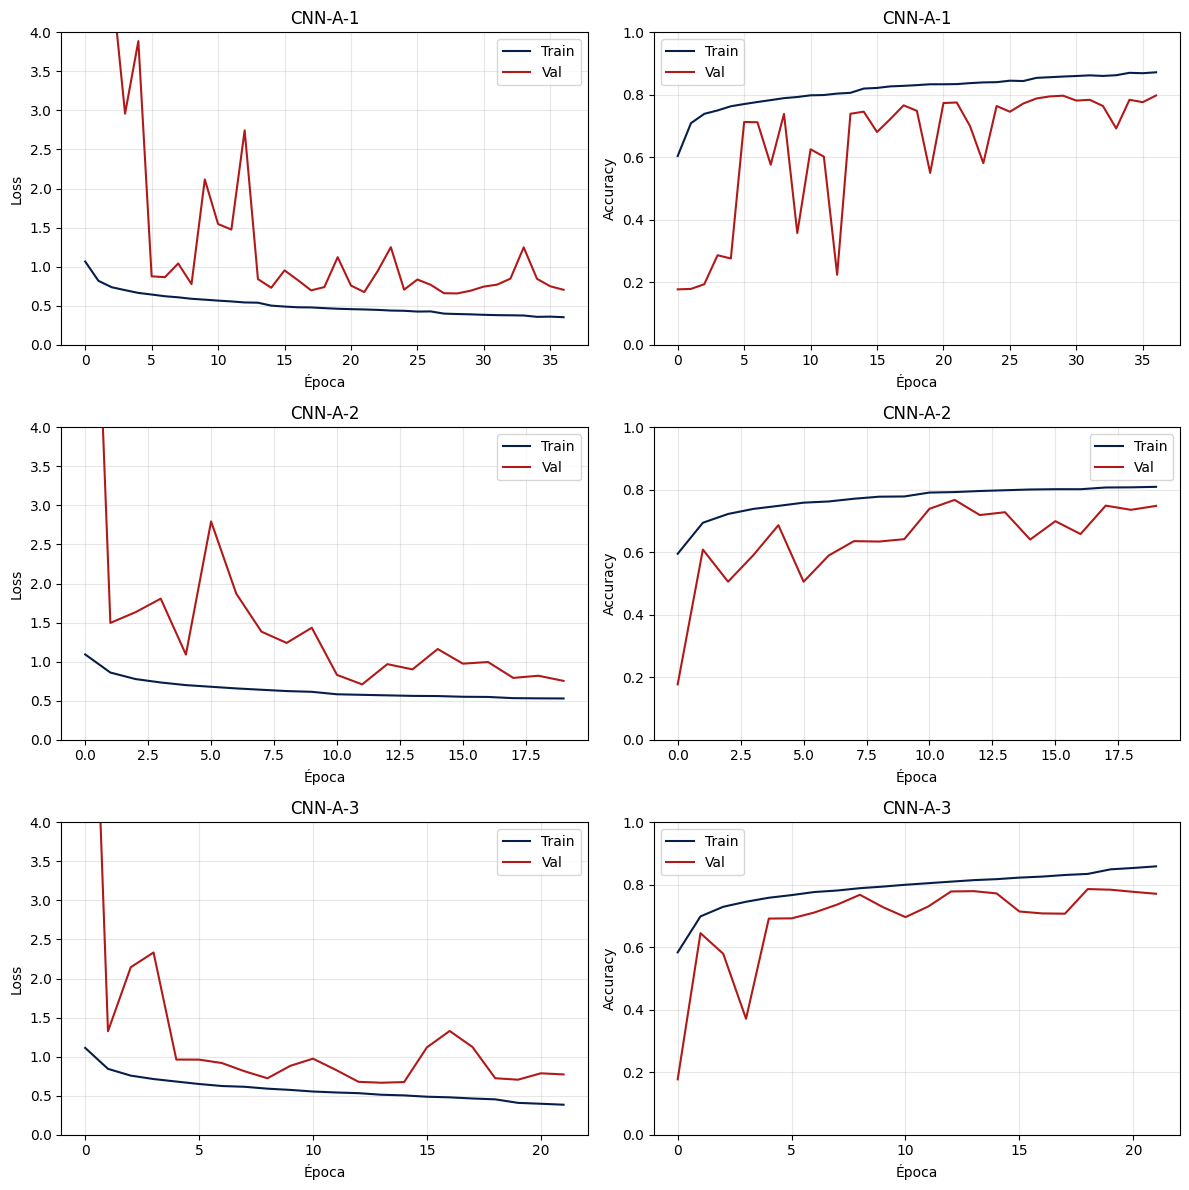

In [19]:
TRAIN_COLOR = '#061F4A'
VAL_COLOR   = '#B11919'

fig, axes = plt.subplots(len(CONFIGS), 2, figsize=(12, 4 * len(CONFIGS)))

for i, cfg in enumerate(CONFIGS):
    run_id = cfg['run_id']
    h = HISTORIES[run_id]

    # Loss
    axes[i, 0].plot(h['loss'],     color=TRAIN_COLOR, label='Train')
    axes[i, 0].plot(h['val_loss'], color=VAL_COLOR,   label='Val')
    axes[i, 0].set_title(run_id)
    axes[i, 0].set_xlabel('Época')
    axes[i, 0].set_ylabel('Loss')
    axes[i, 0].set_ylim(0, 4)
    axes[i, 0].legend()
    axes[i, 0].grid(True, alpha=0.3)

    # Accuracy
    axes[i, 1].plot(h['accuracy'],     color=TRAIN_COLOR, label='Train')
    axes[i, 1].plot(h['val_accuracy'], color=VAL_COLOR,   label='Val')
    axes[i, 1].set_title(run_id)
    axes[i, 1].set_xlabel('Época')
    axes[i, 1].set_ylabel('Accuracy')
    axes[i, 1].set_ylim(0, 1)
    axes[i, 1].legend()
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### **Evaluación en Test**

In [12]:
# ── Evaluación en test ────────────────────────────────────────────────────────
y_true = np.concatenate([y for x, y in test_data], axis=0)

EVAL = {}
for cfg in CONFIGS:
    run_id = cfg['run_id']
    model  = tf.keras.models.load_model(MODELS_PATH / f'{run_id}.keras')

    y_pred = np.argmax(model.predict(test_data, verbose=0), axis=1)
    test_loss, test_acc = model.evaluate(test_data, verbose=0)

    report_row = log_results(run_id, y_true, y_pred, HISTORIES[run_id], test_loss, test_acc, CLASSES)
    EVAL[run_id] = {
        'y_pred':     y_pred,
        'report':     classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True),
        'report_row': report_row,
    }
    del model
    gc.collect()


  CNN-A_results.csv actualizado — CNN-A-1
  CNN-A_results.csv actualizado — CNN-A-2
  CNN-A_results.csv actualizado — CNN-A-3


#### **Matrices de Confusión**

NameError: name 'y_true' is not defined

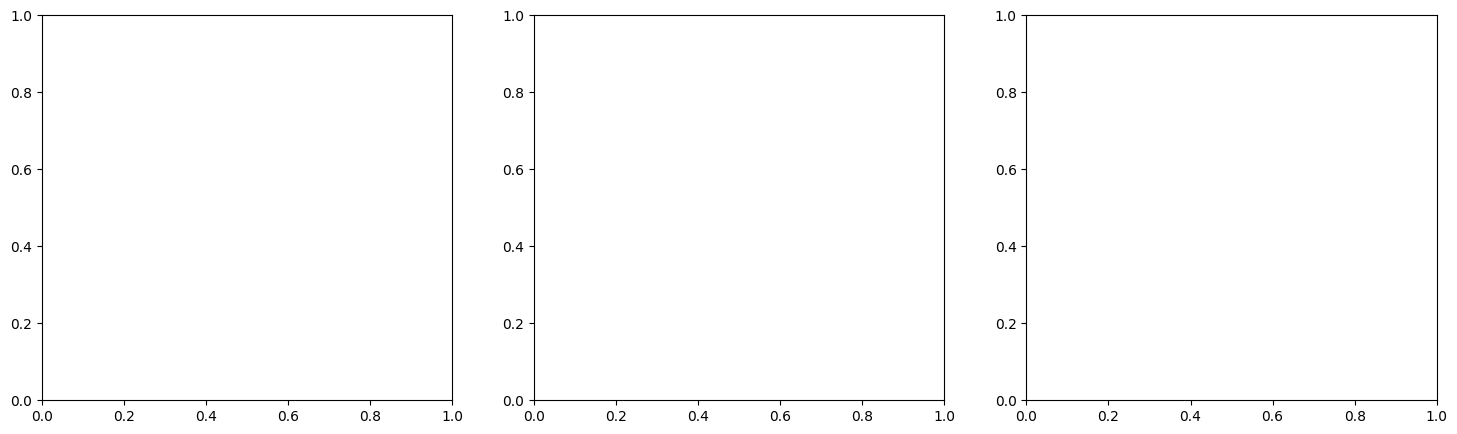

In [20]:
fig, axes = plt.subplots(1, len(CONFIGS), figsize=(6 * len(CONFIGS), 5))

for i, cfg in enumerate(CONFIGS):
    run_id  = cfg['run_id']
    cm_norm = confusion_matrix(y_true, EVAL[run_id]['y_pred'], normalize='true') * 100
    sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='Reds',
                xticklabels=CLASSES, yticklabels=CLASSES,
                vmin=0, vmax=100, ax=axes[i], cbar=False)
    axes[i].set_xlabel('Predicho')
    axes[i].set_ylabel('Real')
    axes[i].set_title(run_id.rsplit('-', 1)[0])

plt.tight_layout()
plt.show()

#### **Tablas de Métricas**

In [14]:
for cfg in CONFIGS:
    run_id    = cfg['run_id']
    df_report = pd.DataFrame(EVAL[run_id]['report']).transpose()
    print(f'\n{run_id}')
    display(df_report.style.format({
        'precision': '{:.3f}',
        'recall':    '{:.3f}',
        'f1-score':  '{:.3f}',
        'support':   '{:.0f}',
    }))



CNN-A-1


,precision,recall,f1-score,support
CD,0.912,0.728,0.810,1814
HYP,0.677,0.605,0.639,572
MI,0.622,0.774,0.690,1006
NORM,0.829,0.882,0.855,3954
STTC,0.789,0.769,0.779,2912
accuracy,0.797,0.797,0.797,1
macro avg,0.766,0.752,0.754,10258
weighted avg,0.804,0.797,0.797,10258



CNN-A-2


,precision,recall,f1-score,support
CD,0.752,0.839,0.793,1814
HYP,0.744,0.355,0.480,572
MI,0.670,0.671,0.670,1006
NORM,0.750,0.924,0.828,3954
STTC,0.843,0.602,0.703,2912
accuracy,0.761,0.761,0.761,1
macro avg,0.752,0.678,0.695,10258
weighted avg,0.768,0.761,0.751,10258



CNN-A-3


,precision,recall,f1-score,support
CD,0.855,0.754,0.801,1814
HYP,0.652,0.469,0.545,572
MI,0.749,0.546,0.631,1006
NORM,0.828,0.861,0.844,3954
STTC,0.715,0.836,0.770,2912
accuracy,0.782,0.782,0.782,1
macro avg,0.760,0.693,0.718,10258
weighted avg,0.783,0.782,0.778,10258


In [15]:
# ── Tabla comparativa ────────────────────────────────────────────────────────
comp_rows = []
for cfg in CONFIGS:
    run_id = cfg['run_id']
    row    = EVAL[run_id]['report_row']
    comp = {'run_id': run_id, 'balanced_acc': row['balanced_acc'], 'macro_f1': row['macro_f1']}
    for cls in CLASSES:
        comp[f'f1_{cls}'] = row[f'f1_{cls}']
    comp_rows.append(comp)

df_comp = pd.DataFrame(comp_rows).set_index('run_id')
display(df_comp.style.format('{:.4f}'))


,balanced_acc,macro_f1,f1_CD,f1_HYP,f1_MI,f1_NORM,f1_STTC
run_id,,,,,,,
CNN-A-1,0.7517,0.7544,0.8096,0.6390,0.6897,0.8549,0.7790
CNN-A-2,0.6782,0.6949,0.7933,0.4805,0.6703,0.8277,0.7026
CNN-A-3,0.6928,0.7184,0.8013,0.5453,0.6314,0.8438,0.7704


### **Conclusiones**

_(Completar manualmente luego de ejecutar el notebook)_

- Comparar el ranking de `val_loss` de Optuna vs. el ranking de `balanced_acc`/`macro_f1` en test.
- Seleccionar el modelo ganador (`CNN-A-1`, `CNN-A-2` o `CNN-A-3`) que pasará a la Fase 2, y documentar el motivo de la elección en `notas` de `CNN-A_results.csv`.